# 02 · EDA — Atrasos e lucratividade

**Granularidade:** cada linha do dataset é um *item* de pedido. Status de entrega, dias e cidades são constantes por pedido, então análises de entrega/cidade usam `orders` (1 linha por `Order Id`). Categoria, produto e benefit variam por item, então usam `df`.

**Definições**
- *Late delivery*: `Late_delivery_risk == True` (equivale a `Delivery Status == 'Late delivery'`).
- *Destino*: `Order City` + `Order Country`. *Origem*: `Customer City` + `Customer State`, que pelo dicionário é a loja onde a compra foi registrada.
- *Rankings por taxa* consideram só grupos com pelo menos `MIN_N` pedidos/itens, para evitar cidades com 1 pedido e 100% de atraso.

In [1]:
import sys
from pathlib import Path

import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
from dataco.transform import load_dataco

pd.set_option('display.float_format', '{:,.2f}'.format)
MIN_N = 100

df = load_dataco()
orders = df.drop_duplicates('Order Id')
len(df), len(orders)

(180519, 65752)

In [2]:
def late_rank(frame, keys, min_n=MIN_N):
    g = frame.groupby(keys, observed=True)['Late_delivery_risk'].agg(n='size', late='sum', late_rate='mean')
    return g[g['n'] >= min_n].sort_values('late_rate', ascending=False)

## 1. Quais cidades (destino) sofrem mais com late delivery?

In [3]:
dest = ['Order City', 'Order Country']
late_rank(orders, dest).head(15)

,,n,late,late_rate
Order City,Order Country,,,
Riyadh,Arabia Saudí,120,76,0.63
Seúl,Corea del Sur,131,82,0.63
Casablanca,Marruecos,105,65,0.62
Daca,Bangladés,130,80,0.62
Turin,Italia,101,62,0.61
Apopa,El Salvador,134,82,0.61
Gold Coast,Australia,262,159,0.61
Toulouse,Francia,122,73,0.60
San Diego,Estados Unidos,147,87,0.59


Em volume absoluto de pedidos atrasados:

In [4]:
late_rank(orders, dest, min_n=1).sort_values('late', ascending=False).head(15)

,,n,late,late_rate
Order City,Order Country,,,
New York City,Estados Unidos,742,416,0.56
Santo Domingo,República Dominicana,744,412,0.55
Manila,Filipinas,617,338,0.55
Los Angeles,Estados Unidos,628,324,0.52
Tegucigalpa,Honduras,578,314,0.54
Managua,Nicaragua,556,311,0.56
Mexico City,México,502,276,0.55
Yakarta,Indonesia,469,261,0.56
London,Reino Unido,437,247,0.57


## 2. Quais cidades têm mais entregas?

Pedidos com envio cancelado não contam como entrega.

In [5]:
delivered = orders[orders['Delivery Status'] != 'Shipping canceled']
delivered.value_counts(dest).head(15).rename('entregas').to_frame()

,,entregas
Order City,Order Country,
Santo Domingo,República Dominicana,715
New York City,Estados Unidos,714
Los Angeles,Estados Unidos,605
Manila,Filipinas,587
Tegucigalpa,Honduras,555
Managua,Nicaragua,524
Mexico City,México,476
Yakarta,Indonesia,447
Philadelphia,Estados Unidos,421


## 3. Quais categorias têm maior late delivery? (por item)

In [6]:
late_rank(df, 'Category Name').head(15)

,n,late,late_rate
Category Name,,,
Lacrosse,343,206,0.60
Pet Supplies,492,290,0.59
Cameras,592,344,0.58
Strength Training,111,64,0.58
Music,434,248,0.57
Accessories,1780,1014,0.57
Fitness Accessories,309,176,0.57
Books,405,229,0.57
Women's Clothing,650,367,0.56


## 4. Quais origens têm mais late delivery?

In [7]:
origin = ['Customer City', 'Customer State']
late_rank(orders, origin).head(15)

,,n,late,late_rate
Customer City,Customer State,,,
Baltimore,MD,198,132,0.67
San Bernardino,CA,102,66,0.65
Simi Valley,CA,100,62,0.62
Amarillo,TX,109,67,0.61
Garden Grove,CA,108,66,0.61
Virginia Beach,VA,262,158,0.60
Riverside,CA,155,92,0.59
Long Beach,CA,192,113,0.59
Orlando,FL,148,87,0.59


In [8]:
late_rank(orders, origin, min_n=1).sort_values('late', ascending=False).head(15)

,,n,late,late_rate
Customer City,Customer State,,,
Caguas,PR,24365,13367,0.55
Chicago,IL,1387,792,0.57
Los Angeles,CA,1248,690,0.55
Brooklyn,NY,1250,674,0.54
New York,NY,640,349,0.55
Bronx,NY,538,300,0.56
Philadelphia,PA,563,300,0.53
Houston,TX,479,260,0.54
Miami,FL,474,257,0.54


## 5. Quanto é o atraso em média?

Atraso = `Days for shipping (real)` − `Days for shipment (scheduled)`, nos pedidos atrasados.

In [9]:
late = orders[orders['Late_delivery_risk']].assign(
    delay_days=lambda d: d['Days for shipping (real)'] - d['Days for shipment (scheduled)'])
late['delay_days'].describe()

count   36,048.00
mean         1.62
std          0.88
min          1.00
25%          1.00
50%          1.00
75%          2.00
max          4.00
Name: delay_days, dtype: float64

In [10]:
late['delay_days'].value_counts().sort_index().rename('pedidos').to_frame()

,pedidos
delay_days,
1,21130
2,10010
3,2452
4,2456


In [11]:
late.groupby('Shipping Mode', observed=True)['delay_days'].agg(['count', 'mean']).join(
    orders.groupby('Shipping Mode', observed=True)['Late_delivery_risk'].mean().rename('late_rate'))

,count,mean,late_rate
Shipping Mode,,,
First Class,9602,1.00,0.95
Same Day,1648,1.00,0.46
Second Class,9803,2.50,0.77
Standard Class,14995,1.50,0.38


## 6. Proporção de benefit negativo × positivo e resultado geral

In [12]:
sign = pd.cut(df['Benefit per order'], [-float('inf'), -1e-9, 1e-9, float('inf')],
              labels=['negativo', 'zero', 'positivo'])
df['benefit_sign'] = sign
sign.value_counts(normalize=True).rename('proporção').to_frame().join(sign.value_counts().rename('itens'))

,proporção,itens
Benefit per order,,
positivo,0.81,145558
negativo,0.19,33784
zero,0.01,1177


In [13]:
pd.Series({
    'receita (Order Item Total)': df['Order Item Total'].sum(),
    'lucro bruto (benefit > 0)': df.loc[df['Benefit per order'] > 0, 'Benefit per order'].sum(),
    'prejuízo (benefit < 0)': df.loc[df['Benefit per order'] < 0, 'Benefit per order'].sum(),
    'resultado líquido': df['Benefit per order'].sum(),
    'margem líquida (%)': 100 * df['Benefit per order'].sum() / df['Order Item Total'].sum(),
}).to_frame('valor')

,valor
receita (Order Item Total),"33,054,402.38"
lucro bruto (benefit > 0),"7,850,450.32"
prejuízo (benefit < 0),"-3,883,547.35"
resultado líquido,"3,966,902.97"
margem líquida (%),12.00


## 7. Dos itens com benefit negativo, quantos têm late delivery?

In [14]:
pd.crosstab(df['benefit_sign'], df['Late_delivery_risk'], margins=True)

Late_delivery_risk,False,True,All
benefit_sign,,,
negativo,15231,18553,33784
zero,550,627,1177
positivo,65761,79797,145558
All,81542,98977,180519


In [15]:
pd.crosstab(df['benefit_sign'], df['Late_delivery_risk'], normalize='index').rename(
    columns={False: 'no prazo/cancelado', True: 'late'})

Late_delivery_risk,no prazo/cancelado,late
benefit_sign,,
negativo,0.45,0.55
zero,0.47,0.53
positivo,0.45,0.55


## 8. Quais categorias dão mais prejuízo?

`prejuízo` = soma dos benefits negativos; `líquido` = soma de todos os benefits.

In [16]:
def loss_rank(keys):
    b = df['Benefit per order']
    return (df.assign(loss=b.where(b < 0, 0), neg=b < 0)
              .groupby(keys, observed=True)
              .agg(itens=('Order Item Id', 'size'), itens_negativos=('neg', 'sum'),
                   prejuízo=('loss', 'sum'), líquido=('Benefit per order', 'sum'),
                   receita=('Order Item Total', 'sum'))
              .assign(pct_negativos=lambda d: d['itens_negativos'] / d['itens'])
              .sort_values('prejuízo'))

loss_rank('Category Name').head(15)

,itens,itens_negativos,prejuízo,líquido,receita,pct_negativos
Category Name,,,,,,
Fishing,17325,3209,"-728,570.95","756,220.77","6,226,935.29",0.19
Cleats,24551,4590,"-452,594.21","494,636.92","3,982,856.50",0.19
Camping & Hiking,13729,2590,"-443,082.23","427,455.57","3,700,783.63",0.19
Cardio Equipment,12487,2332,"-402,647.26","383,011.10","3,320,250.70",0.19
Water Sports,15540,2924,"-334,569.63","325,146.96","2,798,044.18",0.19
Women's Apparel,21035,3923,"-323,772.87","350,421.03","2,828,708.50",0.19
Men's Footwear,22246,4169,"-309,269.70","311,902.82","2,598,494.42",0.19
Indoor/Outdoor Games,19298,3617,"-298,637.48","318,451.43","2,596,454.02",0.19
Shop By Sport,10984,2154,"-144,310.56","129,813.96","1,177,185.63",0.20


## 9. Quais produtos dão mais prejuízo?

In [17]:
loss_rank('Product Name').head(15)

,itens,itens_negativos,prejuízo,líquido,receita,pct_negativos
Product Name,,,,,,
Field & Stream Sportsman 16 Gun Fire Safe,17325,3209,"-728,570.95","756,220.77","6,226,935.29",0.19
Perfect Fitness Perfect Rip Deck,24515,4583,"-450,978.29","493,828.30","3,973,180.36",0.19
Diamondback Women's Serene Classic Comfort Bi,13729,2590,"-443,082.23","427,455.57","3,700,783.63",0.19
Nike Men's Free 5.0+ Running Shoe,12169,2271,"-400,015.04","379,915.82","3,295,693.30",0.19
Pelican Sunstream 100 Kayak,15500,2916,"-332,804.25","324,076.37","2,785,518.09",0.19
Nike Men's Dri-FIT Victory Golf Polo,21035,3923,"-323,772.87","350,421.03","2,828,708.50",0.19
Nike Men's CJ Elite 2 TD Football Cleat,22246,4169,"-309,269.70","311,902.82","2,598,494.42",0.19
O'Brien Men's Neoprene Life Vest,19298,3617,"-298,637.48","318,451.43","2,596,454.02",0.19
Under Armour Girls' Toddler Spine Surge Runni,10617,2085,"-139,661.49","126,278.51","1,140,770.96",0.20


## 10. Pareto — categorias × lucro e prejuízo

Um eixo só, em %: barra = participação da categoria no total; linha = acumulado. Categorias depois de 95% do acumulado são agrupadas em *Outras*.

In [18]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

INK, MUTED, GRID = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': MUTED,
                     'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED,
                     'text.color': INK, 'font.size': 9})


def pareto(values, title, color, cutoff=0.95):
    s = values.sort_values(ascending=False)
    share = s / s.sum()
    keep = share.cumsum().shift(fill_value=0) < cutoff
    if (~keep).any():
        share = pd.concat([share[keep], pd.Series({f'Outras ({(~keep).sum()})': share[~keep].sum()})])
    cum = share.cumsum()
    y = range(len(share))
    fig, ax = plt.subplots(figsize=(9, 0.32 * len(share) + 1.2))
    ax.barh(y, share, height=0.6, color=color, label='participação')
    ax.plot(cum, y, color=INK, lw=2, marker='o', ms=4, label='acumulado')
    ax.axvline(0.8, color=MUTED, lw=1, ls='--')
    ax.text(0.8, -0.9, ' 80%', color=MUTED, va='bottom')
    for i, (v, c) in enumerate(zip(share, cum)):
        ax.text(v + 0.005, i, f'{v:.0%}', va='center', color=MUTED, fontsize=8)
    ax.set_yticks(list(y), share.index)
    ax.invert_yaxis()
    ax.set_xlim(0, 1.02)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
    ax.grid(axis='x', color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.set_title(f'{title} — total ${s.sum() / 1e6:,.2f}M', loc='left', fontsize=11)
    ax.legend(loc='lower right', frameon=False)
    fig.tight_layout()
    return fig


b = df['Benefit per order']
by_cat = df.assign(lucro=b.clip(lower=0), prejuizo=-b.clip(upper=0)).groupby('Category Name', observed=True)

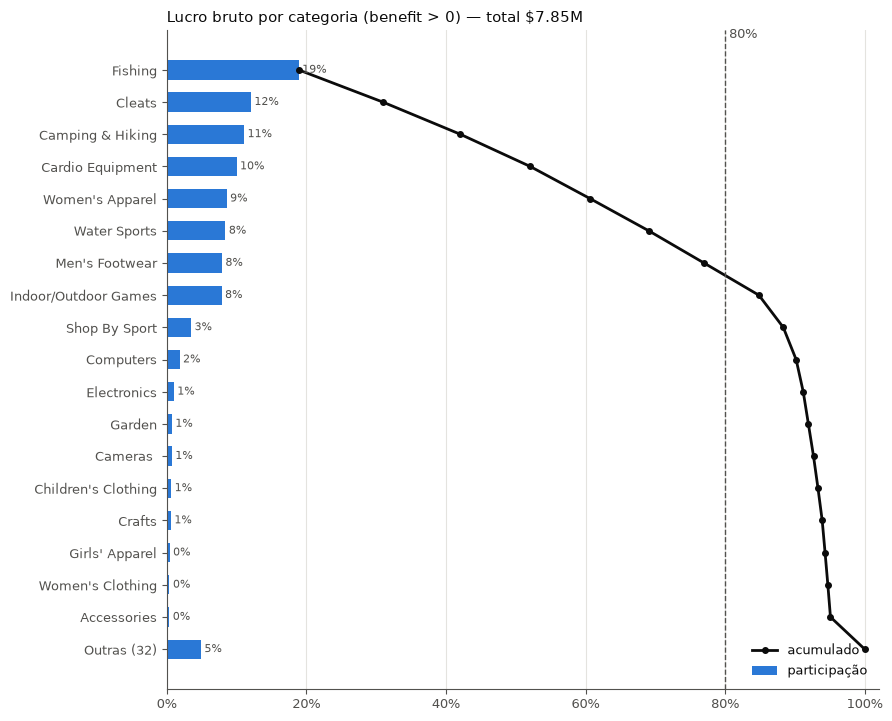

In [19]:
pareto(by_cat['lucro'].sum(), 'Lucro bruto por categoria (benefit > 0)', '#2a78d6');

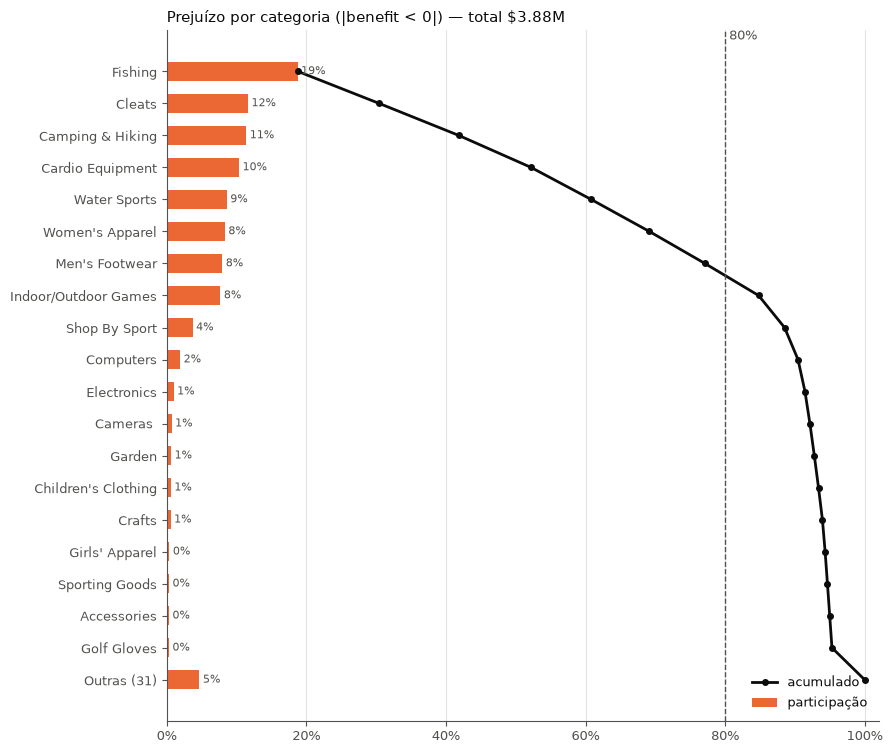

In [20]:
pareto(by_cat['prejuizo'].sum(), 'Prejuízo por categoria (|benefit < 0|)', '#eb6834');

## 11. Datas

- `order date (DateOrders)`: data e hora em que o pedido foi feito.
- `shipping date (DateOrders)`: data e hora de fim do envio. É sempre a data do pedido + `Days for shipping (real)`, então marca a entrega, não a saída do armazém.

Volume e taxa de atraso têm escalas diferentes, então ficam em dois painéis com o mesmo eixo de tempo.

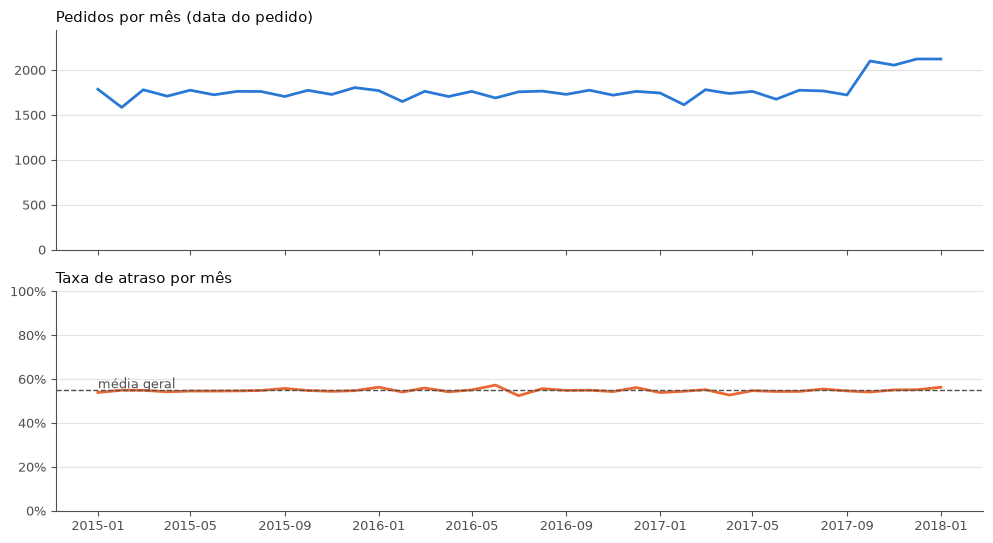

In [21]:
monthly = orders.set_index('order date (DateOrders)').resample('MS').agg(
    pedidos=('Order Id', 'size'), late_rate=('Late_delivery_risk', 'mean'))

fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
a1.plot(monthly.index, monthly['pedidos'], color='#2a78d6', lw=2)
a1.set_title('Pedidos por mês (data do pedido)', loc='left', fontsize=11)
a1.set_ylim(0, monthly['pedidos'].max() * 1.15)
a2.plot(monthly.index, monthly['late_rate'], color='#eb6834', lw=2)
a2.axhline(orders['Late_delivery_risk'].mean(), color=MUTED, lw=1, ls='--')
a2.text(monthly.index[0], orders['Late_delivery_risk'].mean() + 0.01, 'média geral', color=MUTED)
a2.set_title('Taxa de atraso por mês', loc='left', fontsize=11)
a2.set_ylim(0, 1)
a2.yaxis.set_major_formatter(mtick.PercentFormatter(1))
for ax in (a1, a2):
    ax.grid(axis='y', color=GRID, lw=0.8)
    ax.set_axisbelow(True)
fig.tight_layout();

## 12. Prazos por modo de envio — dias reais × prazo agendado

Só pedidos não cancelados (cancelados não têm entrega).

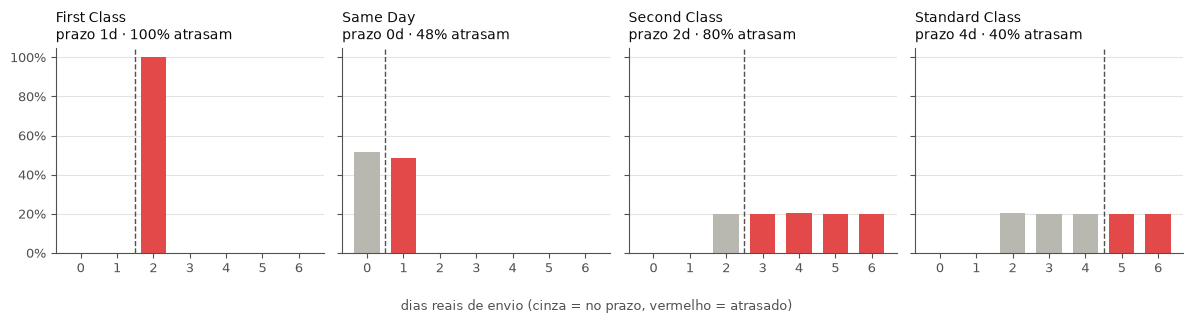

In [22]:
shipped = orders[orders['Delivery Status'] != 'Shipping canceled']
real, sched = 'Days for shipping (real)', 'Days for shipment (scheduled)'
dist = pd.crosstab(shipped['Shipping Mode'], shipped[real], normalize='index')
sched_by_mode = shipped.groupby('Shipping Mode', observed=True)[sched].first()

fig, axes = plt.subplots(1, len(dist), figsize=(12, 3.2), sharey=True)
for ax, (mode, row) in zip(axes, dist.iterrows()):
    s = sched_by_mode[mode]
    ax.bar(row.index, row.values, width=0.7, color=['#e34948' if d > s else '#b8b7b0' for d in row.index])
    ax.axvline(s + 0.5, color=MUTED, lw=1, ls='--')
    ax.set_title(f'{mode}\nprazo {s}d · {row[row.index > s].sum():.0%} atrasam', loc='left', fontsize=10)
    ax.set_xticks(range(7))
    ax.grid(axis='y', color=GRID, lw=0.8)
    ax.set_axisbelow(True)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1))
fig.supxlabel('dias reais de envio (cinza = no prazo, vermelho = atrasado)', fontsize=9, color=MUTED)
fig.tight_layout();

% de pedidos entregues dentro de um prazo de *k* dias — base para propor novos prazos:

In [23]:
pd.DataFrame({k: shipped.groupby('Shipping Mode', observed=True)[real].apply(lambda s: (s <= k).mean())
              for k in range(7)}).rename_axis(columns='prazo (dias)')

prazo (dias),0,1,2,3,4,5,6
Shipping Mode,,,,,,,
First Class,0.00,0.00,1.00,1.00,1.00,1.00,1.00
Same Day,0.52,1.00,1.00,1.00,1.00,1.00,1.00
Second Class,0.00,0.00,0.20,0.40,0.60,0.80,1.00
Standard Class,0.00,0.00,0.20,0.40,0.60,0.80,1.00


## 13. Lucro por mercado, região, tipo de pagamento e status

`SUSPECTED_FRAUD` e `CANCELED` nunca são enviados, mas registram receita e benefit.

In [24]:
def margin(keys):
    b = df['Benefit per order']
    return (df.assign(neg=b < 0).groupby(keys, observed=True)
              .agg(itens=('Order Item Id', 'size'), pct_negativos=('neg', 'mean'),
                   líquido=('Benefit per order', 'sum'), receita=('Order Item Total', 'sum'))
              .assign(margem=lambda d: d['líquido'] / d['receita'])
              .sort_values('margem'))

margin('Market')

,itens,pct_negativos,líquido,receita,margem
Market,,,,,
Pacific Asia,41260,0.19,"857,753.44","7,434,262.65",0.12
Europe,50252,0.19,"1,169,442.96","9,769,198.32",0.12
LATAM,51594,0.19,"1,123,321.61","9,235,762.09",0.12
Africa,11614,0.19,"252,071.18","2,061,679.39",0.12
USCA,25799,0.19,"564,313.78","4,553,499.92",0.12


In [25]:
margin('Order Region')

,itens,pct_negativos,líquido,receita,margem
Order Region,,,,,
Eastern Asia,7280,0.19,"147,368.01","1,334,313.41",0.11
Oceania,10148,0.19,"201,478.02","1,809,996.55",0.11
West Asia,6009,0.19,"118,815.41","1,056,080.99",0.11
North Africa,3232,0.19,"64,599.86","572,241.97",0.11
Central Africa,1677,0.20,"33,447.27","292,912.56",0.11
Eastern Europe,3920,0.20,"79,717.05","696,307.19",0.11
Caribbean,8318,0.19,"171,825.64","1,481,668.69",0.12
West of USA,7993,0.19,"164,940.66","1,412,253.60",0.12
Western Europe,27109,0.19,"625,446.08","5,296,002.89",0.12


In [26]:
margin('Type')

,itens,pct_negativos,líquido,receita,margem
Type,,,,,
PAYMENT,41725,0.19,"887,239.03","7,631,851.80",0.12
TRANSFER,49883,0.19,"1,091,034.06","9,165,574.30",0.12
DEBIT,69295,0.19,"1,530,648.79","12,639,509.43",0.12
CASH,19616,0.18,"457,981.09","3,617,466.85",0.13


In [27]:
margin('Order Status')

,itens,pct_negativos,líquido,receita,margem
Order Status,,,,,
CANCELED,3692,0.19,"75,345.63","668,244.99",0.11
SUSPECTED_FRAUD,4062,0.20,"85,136.71","741,492.32",0.11
PENDING_PAYMENT,39832,0.19,"843,810.24","7,286,275.64",0.12
ON_HOLD,9804,0.20,"208,913.04","1,780,237.70",0.12
PENDING,20227,0.19,"435,725.85","3,704,456.23",0.12
COMPLETE,59491,0.19,"1,321,735.75","10,859,271.73",0.12
PROCESSING,21902,0.18,"494,825.87","4,051,380.77",0.12
PAYMENT_REVIEW,1893,0.19,"43,428.79","345,576.16",0.13
CLOSED,19616,0.18,"457,981.09","3,617,466.85",0.13


In [28]:
not_shipped = df['Order Status'].isin(['CANCELED', 'SUSPECTED_FRAUD'])
df.groupby(not_shipped.rename('cancelado/fraude'))[['Order Item Total', 'Benefit per order']].sum()

,Order Item Total,Benefit per order
cancelado/fraude,,
False,"31,644,665.08","3,806,420.63"
True,"1,409,737.30","160,482.34"


## 14. Atraso × dia da semana e hora do pedido, por modo

Taxa de atraso dentro de cada modo, para não confundir com a mistura de modos.

In [29]:
od = orders['order date (DateOrders)']
orders.pivot_table(index=od.dt.day_name().rename('dia'), columns='Shipping Mode',
                   values='Late_delivery_risk', aggfunc='mean', observed=True)

Shipping Mode,First Class,Same Day,Second Class,Standard Class
dia,,,,
Friday,0.95,0.51,0.77,0.38
Monday,0.94,0.43,0.76,0.39
Saturday,0.95,0.47,0.76,0.38
Sunday,0.96,0.45,0.76,0.38
Thursday,0.96,0.46,0.76,0.38
Tuesday,0.95,0.45,0.78,0.38
Wednesday,0.96,0.46,0.78,0.38


In [30]:
hour = pd.cut(od.dt.hour, [0, 6, 12, 18, 24], right=False, labels=['0-6h', '6-12h', '12-18h', '18-24h']).rename('hora')
orders.pivot_table(index=hour, columns='Shipping Mode', values='Late_delivery_risk', aggfunc='mean', observed=True)

Shipping Mode,First Class,Same Day,Second Class,Standard Class
hora,,,,
0-6h,0.95,0.00,0.77,0.38
6-12h,0.95,0.00,0.77,0.38
12-18h,0.95,0.96,0.77,0.38
18-24h,0.96,0.95,0.77,0.38


**Same Day:** pedidos antes das 12h atrasam 0%; depois das 12h, cerca de 95% — corte oculto ao meio-dia.